# 03 Analyse: cost benchmark
Which towns cost more than they should, given who lives there? Which care types cause it? Does poor health explain it?

In [1]:
# Libraries
import pandas as pd
import matplotlib.pyplot as plt

## Step 1. Reference rates: national cost per insured-year by sex and age

In [2]:
# Load the clean Vektis table
vektis = pd.read_csv("../data/processed/vektis_clean.csv")

In [3]:
# Check Vektis shape
vektis.shape

(12991, 45)

In [4]:
# One row per age(19 age bands) and sex(2, m,v ) group = 38 groups(2*19), total cost and insured-year
# Right now I have 12,991 rows (one per town × sex × age). I want 38

# National totals per sex and age group: sum cost and insured-years over all towns
rates = vektis.groupby(["geslacht", "age_from"])[["cost_total", "aantal_verzekerdejaren"]].sum()

rates.shape

(38, 2)

In [5]:
# rate = the national average cost per person (per insured-year) for one sex and age group. 
# Reference rate: national average cost per insured-year, per sex and age group
rates["rate"] = rates["cost_total"] / rates["aantal_verzekerdejaren"]

In [6]:
# Move sex and age out of the index into normal columns, so they can be filtered and plotted
rates_flat = rates.reset_index()

rates_flat.shape

(38, 5)

In [7]:
# One table per sex, so each gets its own line in the chart
men = rates_flat[rates_flat["geslacht"] == "M"]
women = rates_flat[rates_flat["geslacht"] == "V"]
len(men), len(women)

(19, 19)

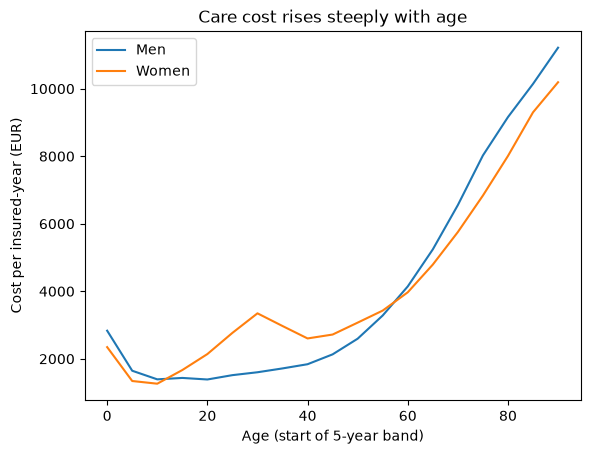

In [8]:
# Sanity chart: national cost per insured-year by age, one line per sex
plt.plot(men["age_from"], men["rate"], label="Men")
plt.plot(women["age_from"], women["rate"], label="Women")
plt.xlabel("Age (start of 5-year band)")
plt.ylabel("Cost per insured-year (EUR)")
plt.title("Care cost rises steeply with age")
plt.legend()
plt.show()


Cost per person depends heavily on age and sex: a man of 90 costs about 8 times as much as a man of 20. So a town's raw cost mostly reflects who lives there. To compare towns fairly, each town must be measured against what its own age and sex mix would cost.



## Step 2. Expected cost and cost index per town

In [9]:
# Adding the rate column (the national average cost per insured-year for each sex and age group) from rates_flat to the Vektis table, matched on geslacht and age_from
# Give every Vektis row the national rate of its own sex and age group
# Take only the 2 key columns and the rate from rates_flat, so no _x/_y columns appear
vektis_rated = pd.merge(vektis, rates_flat[["geslacht", "age_from", "rate"]], on=["geslacht", "age_from"], how="left")


In [10]:
# Check: still 12,991 rows (one new column, rate) and no row without a rate
print("Shape:", vektis_rated.shape)
print("Rows without a rate:", vektis_rated["rate"].isna().sum())
assert len(vektis_rated) == 12991
assert vektis_rated["rate"].notna().all()


Shape: (12991, 46)
Rows without a rate: 0


In [11]:
# Expected cost per row: insured-years x national rate of that sex and age group
vektis_rated["expected"] = vektis_rated["aantal_verzekerdejaren"] * vektis_rated["rate"]

In [12]:
# Check: national expected cost must equal national actual cost (rates came from the same data)
print("Expected total:", round(vektis_rated["expected"].sum()))
print("Actual total:  ", round(vektis_rated["cost_total"].sum()))

# The rates were made from this same data (national cost ÷ national insured-years per group). Multiplying back by the same insured-years and adding everything up gives the same total. If they differed, the merge in 2a would be wrong.

Expected total: 59357400091
Actual total:   59357400091


In [13]:
# One row per town: add up actual cost, expected cost and insured-years over all sex and age groups
vektis_town = vektis_rated.groupby(["Key", "gemeentenaam"])[["cost_total", "expected", "aantal_verzekerdejaren"]].sum().reset_index()

In [14]:
# Check: 342 towns, 5 columns; look at Amsterdam
print("Shape:", vektis_town.shape)
assert len(vektis_town) == 342
vektis_town[vektis_town["Key"] == "GM0363"]

Shape: (342, 5)


,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren
106,GM0363,AMSTERDAM,2.756174e+09,2.682914e+09,887918.59


In [15]:
# KPIs per town
# Per person: divide each total by the town's insured-years

# actual_per_person: what one insured-year really cost in this town
vektis_town["actual_per_person"] = vektis_town["cost_total"] / vektis_town["aantal_verzekerdejaren"]

# expected_per_person: what it would cost at the national rates
vektis_town["expected_per_person"] = vektis_town["expected"] / vektis_town["aantal_verzekerdejaren"]

# cost_index: actual ÷ expected × 100. The headline KPI
vektis_town["cost_index"] = vektis_town["cost_total"] / vektis_town["expected"] * 100

# excess: actual − expected, in euros: how much money the gap is
vektis_town["excess"] = vektis_town["cost_total"] - vektis_town["expected"]

In [16]:
# Check: Amsterdam (GM0363) and Utrecht (GM0344)
vektis_town[vektis_town["Key"].isin(["GM0363", "GM0344"])]

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess
96,GM0344,UTRECHT,1.053971e+09,1.029987e+09,363686.77,2898.019557,2832.070660,102.328646,2.398474e+07
106,GM0363,AMSTERDAM,2.756174e+09,2.682914e+09,887918.59,3104.084035,3021.576103,102.730626,7.326033e+07


**What the KPIs say for the two biggest cities:** after adjusting for age and sex, Amsterdam costs 2.7% more than its population mix predicts (cost index 102.7), about €73 million a year above expected. Utrecht is 2.3% above expected (index 102.3), about €24 million. Both indexes are close to 100, but because these cities are large, a small percentage is a lot of money. This is why the benchmark shows the index and the euros side by side.


In [17]:
# Stop if national expected and actual totals differ (would mean the merge in 2a is wrong)
assert round(vektis_rated["expected"].sum()) == round(vektis_rated["cost_total"].sum()), "Expected total does not equal actual total"

In [18]:
# Peek at the town table: one row per town with actual, expected and insured-years
vektis_town.head()

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess
0,GM0014,GRONINGEN,7.360728e+08,7.011526e+08,228482.93,3221.565753,3068.730996,104.980390,3.492013e+07
1,GM0034,ALMERE,6.832099e+08,6.657136e+08,222940.28,3064.542090,2986.062575,102.628194,1.749625e+07
2,GM0037,STADSKANAAL,1.394910e+08,1.164892e+08,31289.31,4458.105281,3722.972022,119.745871,2.300181e+07
3,GM0047,VEENDAM,1.142761e+08,9.746109e+07,27376.82,4174.190746,3559.985654,117.253022,1.681498e+07
4,GM0050,ZEEWOLDE,6.930273e+07,7.354691e+07,23206.62,2986.334531,3169.220939,94.229294,-4.244175e+06


In [19]:
# Checksums: the whole country compared with itself must come out exactly as expected. a test to chcek if the benchmark is wired correctly
# If the whole country is compared with itself, it must come out exactly as expected: index 100, excess €0. If not, something is wrong, and every finding after this would be wrong too

# National cost index: total actual / total expected x 100, as if the country were one town
national_index = vektis_town["cost_total"].sum() / vektis_town["expected"].sum() * 100

# Total excess: add up the excess of all 342 towns (above and below expected cancel out)
total_excess = vektis_town["excess"].sum()

print("National cost index:", round(national_index, 1))
print("Total excess (EUR):", round(total_excess))

# Stop if either checksum fails
assert round(national_index, 1) == 100, "National index is not 100: check the expected cost"
assert round(total_excess) == 0, "Total excess is not 0: check the expected cost"

National cost index: 100.0
Total excess (EUR): 0


In [20]:
# The spread of the cost index across towns: expect min about 77, max about 125, median about 97
vektis_town["cost_index"].describe()

count    342.000000
mean      97.414438
std        7.108902
min       77.471100
25%       92.861894
50%       96.836937
75%      101.495449
max      125.417237
Name: cost_index, dtype: float64

The big cities (Amsterdam, Utrecht) sit above 100, and they carry a large share of all the money. Because the national index is exactly 100, the many small towns must sit slightly below 100 to balance them. The median counts every town once, the national index counts every euro once, so the median town comes out at 96.8.



In [21]:
# KPIs per care type. The per-care-type index says what causes it

# Step 2f-1: reshape from wide to long, one row per town x sex x age x care type
# The 10 care-type group columns made in 02_clean, Step 5
care_types = ["Hospital care", "Pharmacy", "GP care", "Mental health", "Nursing and rehabilitation",
              "Paramedical", "Aids and dental", "Maternity", "Care abroad", "Transport and other"]

# id_vars stay as they are in every row; the 10 care-type columns become two columns: care_type and cost
vektis_long = vektis.melt(id_vars=["Key", "gemeentenaam", "geslacht", "age_from", "aantal_verzekerdejaren"],
                          value_vars=care_types, var_name="care_type", value_name="cost")

In [22]:
# Check: 12,991 rows x 10 care types = 129,910 rows, 7 columns; the cost still adds up to the national total
print("Shape:", vektis_long.shape)
assert len(vektis_long) == 12991 * 10
assert round(vektis_long["cost"].sum()) == round(vektis["cost_total"].sum()), "Melt lost or added cost"
vektis_long.head(3)

Shape: (129910, 7)


,Key,gemeentenaam,geslacht,age_from,aantal_verzekerdejaren,care_type,cost
0,GM1680,AA EN HUNZE,M,0,462.82,Hospital care,594197.18
1,GM0358,AALSMEER,M,0,665.75,Hospital care,1829500.58
2,GM0197,AALTEN,M,0,596.80,Hospital care,862338.30


In [23]:
# Step 2f-2: national reference rate per care type x sex x age group
# National totals: sum cost and insured-years over all towns, per care type, sex and age
rates_ct = vektis_long.groupby(["care_type", "geslacht", "age_from"])[["cost", "aantal_verzekerdejaren"]].sum()

# Rate: national average cost per insured-year for that care type, sex and age group
rates_ct["rate"] = rates_ct["cost"] / rates_ct["aantal_verzekerdejaren"]

# Move care type, sex and age out of the index into normal columns, for the merge in 2f-3
rates_ct_flat = rates_ct.reset_index()


In [24]:
# Check: 10 care types x 38 groups = 380 rates
print("Shape:", rates_ct_flat.shape)
assert len(rates_ct_flat) == 380
rates_ct_flat.head(3)

Shape: (380, 6)


,care_type,geslacht,age_from,cost,aantal_verzekerdejaren,rate
0,Aids and dental,M,0,3.050211e+07,390153.04,78.179860
1,Aids and dental,M,5,1.244383e+08,448758.44,277.294675
2,Aids and dental,M,10,1.375595e+08,474631.49,289.823700


In [25]:
# Step 2f-3: give every row the national rate of its own care type, sex and age group
# Take only the 3 key columns and the rate from rates_ct_flat, so no _x/_y columns appear
vektis_long_rated = pd.merge(vektis_long, rates_ct_flat[["care_type", "geslacht", "age_from", "rate"]],
                             on=["care_type", "geslacht", "age_from"], how="left")


In [26]:
# Check: still 129,910 rows (one new column, rate) and no row without a rate
print("Shape:", vektis_long_rated.shape)
print("Rows without a rate:", vektis_long_rated["rate"].isna().sum())
assert len(vektis_long_rated) == 129910, "The merge added rows: check on= has all 3 keys"
assert vektis_long_rated["rate"].notna().all()


Shape: (129910, 8)
Rows without a rate: 0


Each row now has its own insured-years and the national rate for its care type, sex and age, which is everything needed to compute what that row should cost.

In [27]:
# Expected cost per row: insured-years x national rate for that care type, sex and age group
vektis_long_rated["expected"] = vektis_long_rated["aantal_verzekerdejaren"] * vektis_long_rated["rate"]

In [28]:
# Check: national expected cost must equal national actual cost, as in 2b
print("Expected total:", round(vektis_long_rated["expected"].sum()))
print("Actual total:  ", round(vektis_long_rated["cost"].sum()))
assert round(vektis_long_rated["expected"].sum()) == round(vektis_long_rated["cost"].sum()), "Expected total does not equal actual total"

Expected total: 59357400091
Actual total:   59357400091


In [29]:
# Step 2f-5: one row per town and care type: add up actual cost, expected cost and insured-years over all sex and age groups
care_type_town = vektis_long_rated.groupby(["Key", "gemeentenaam", "care_type"])[["cost", "expected", "aantal_verzekerdejaren"]].sum().reset_index()


In [30]:
# Check: 342 towns x 10 care types = 3,420 rows; look at Amsterdam's 10 care types
print("Shape:", care_type_town.shape)
assert len(care_type_town) == 342 * 10
care_type_town[care_type_town["Key"] == "GM0363"]


Shape: (3420, 6)


,Key,gemeentenaam,care_type,cost,expected,aantal_verzekerdejaren
1060,GM0363,AMSTERDAM,Aids and dental,1.206868e+08,1.256469e+08,887918.59
1061,GM0363,AMSTERDAM,Care abroad,2.176847e+07,1.600548e+07,887918.59
1062,GM0363,AMSTERDAM,GP care,2.549129e+08,2.486597e+08,887918.59
1063,GM0363,AMSTERDAM,Hospital care,1.327655e+09,1.376090e+09,887918.59
1064,GM0363,AMSTERDAM,Maternity,4.065125e+07,5.940374e+07,887918.59
1065,GM0363,AMSTERDAM,Mental health,4.177775e+08,3.220836e+08,887918.59
1066,GM0363,AMSTERDAM,Nursing and rehabilitation,1.805427e+08,1.548807e+08,887918.59
1067,GM0363,AMSTERDAM,Paramedical,4.791368e+07,5.143317e+07,887918.59
1068,GM0363,AMSTERDAM,Pharmacy,2.902823e+08,2.756861e+08,887918.59
1069,GM0363,AMSTERDAM,Transport and other,5.398326e+07,5.302394e+07,887918.59


In [31]:
# Step 2f-6: KPIs per town and care type
# Care-type index: actual / expected x 100 for that care type only (100 = exactly as expected)
care_type_town["cost_index"] = care_type_town["cost"] / care_type_town["expected"] * 100

# Excess: actual - expected, in euros, for that care type in that town (positive = above expected)
care_type_town["excess"] = care_type_town["cost"] - care_type_town["expected"]


In [32]:
# Check: Amsterdam's 10 care types, highest excess first
care_type_town[care_type_town["Key"] == "GM0363"].sort_values("excess", ascending=False)


,Key,gemeentenaam,care_type,cost,expected,aantal_verzekerdejaren,cost_index,excess
1065,GM0363,AMSTERDAM,Mental health,4.177775e+08,3.220836e+08,887918.59,129.710882,9.569389e+07
1066,GM0363,AMSTERDAM,Nursing and rehabilitation,1.805427e+08,1.548807e+08,887918.59,116.568851,2.566196e+07
1068,GM0363,AMSTERDAM,Pharmacy,2.902823e+08,2.756861e+08,887918.59,105.294501,1.459621e+07
1062,GM0363,AMSTERDAM,GP care,2.549129e+08,2.486597e+08,887918.59,102.514765,6.253208e+06
1061,GM0363,AMSTERDAM,Care abroad,2.176847e+07,1.600548e+07,887918.59,136.006385,5.762994e+06
1069,GM0363,AMSTERDAM,Transport and other,5.398326e+07,5.302394e+07,887918.59,101.809235,9.593274e+05
1067,GM0363,AMSTERDAM,Paramedical,4.791368e+07,5.143317e+07,887918.59,93.157149,-3.519495e+06
1060,GM0363,AMSTERDAM,Aids and dental,1.206868e+08,1.256469e+08,887918.59,96.052349,-4.960102e+06
1064,GM0363,AMSTERDAM,Maternity,4.065125e+07,5.940374e+07,887918.59,68.432127,-1.875250e+07
1063,GM0363,AMSTERDAM,Hospital care,1.327655e+09,1.376090e+09,887918.59,96.480234,-4.843515e+07


In [33]:
# Step 2f-7: checksum per care type: for each care type, the whole country must come out at excess 0
excess_by_type = care_type_town.groupby("care_type")["excess"].sum()
print(excess_by_type.round(2))

# Stop if any care type does not balance to 0
assert (excess_by_type.round() == 0).all(), "A care type does not balance to 0: check 2f-2 to 2f-4"


care_type
Aids and dental               0.0
Care abroad                  -0.0
GP care                       0.0
Hospital care                -0.0
Maternity                    -0.0
Mental health                -0.0
Nursing and rehabilitation    0.0
Paramedical                   0.0
Pharmacy                      0.0
Transport and other           0.0
Name: excess, dtype: float64


In [34]:
# Step 2g: join the CBS health table, so each town has its cost KPIs and its health value in one row
# Load the clean CBS table (one row per town: health_value, health_low, health_high)
cbs_health = pd.read_csv("../data/processed/cbs_health_clean.csv")

# Same codes, different column names: Key (Vektis) and RegioS (CBS). how="left" keeps all 342 towns
town_kpis = pd.merge(vektis_town, cbs_health, left_on="Key", right_on="RegioS", how="left")


In [35]:
# Check: still 342 towns, and only the 2 islands without a health value
print("Shape:", town_kpis.shape)
print("Towns without health value:", town_kpis["health_value"].isna().sum())
assert len(town_kpis) == 342
assert "cost_index" in town_kpis.columns, "cost_index missing: vektis_town was rebuilt after the KPI cell"
assert town_kpis["health_value"].isna().sum() == 2, "Expected only Schiermonnikoog and Vlieland to be missing"
town_kpis[town_kpis["health_value"].isna()][["Key", "gemeentenaam"]]


Shape: (342, 13)
Towns without health value: 2


,Key,gemeentenaam
12,GM0088,SCHIERMONNIKOOG
15,GM0096,VLIELAND


## Step 3. The size rule

In [36]:
# The small towns (under 10,000 insured-years), most expensive first
small_towns = town_kpis[town_kpis["aantal_verzekerdejaren"] < 10000].sort_values("cost_index", ascending=False)

# Show only the columns we need to judge them
small_towns[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
244,SIMPELVELD,9786.65,100.074477,2.811486e+04
246,VAALS,7311.04,99.504046,-1.501718e+05
273,NOORD-BEVELAND,7774.36,95.246614,-1.453033e+06
88,EEMNES,9781.80,93.466310,-2.218943e+06
241,MOOK EN MIDDELAAR,7917.48,92.167879,-2.414985e+06
191,BAARLE-NASSAU,6917.45,91.521822,-2.229983e+06
127,OOSTZAAN,9585.37,89.049654,-3.669633e+06
93,RENSWOUDE,5488.65,88.224330,-2.021214e+06
6,AMELAND,3709.26,83.276282,-2.257987e+06
15,VLIELAND,1138.95,83.120539,-6.741772e+05


**Finding ** 13 towns have fewer than 10,000 insured-years. 12 of them are below 100; the only exception, Simpelveld, is at 100.1, which is practically exactly 100. The lowest is Rozendaal (77.6). None of them comes close to the top of the ranking, so they are not hiding among the most expensive towns.

The four Wadden islands (Ameland, Vlieland, Terschelling, Schiermonnikoog) all sit around 83. Possible explanations, not yet tested:
- **Access to care:** there is no hospital on the islands, and a ferry trip makes people go to specialists less often. A low index here may mean less care, not more efficient care.
- **Who stays:** very ill or very old islanders often move to the mainland (for example to a nursing home), and their costs then count for their new town.


In [37]:
# Mark which towns are big enough for the priority list (10,000 insured-years or more)
town_kpis["passes_size_rule"] = town_kpis["aantal_verzekerdejaren"] >= 10000

# Check: 329 towns pass, the 13 small towns from 3a do not, and no town was lost
print(town_kpis["passes_size_rule"].value_counts())
assert (town_kpis["passes_size_rule"] == False).sum() == 13, "Expected 13 small towns: check the cut-off"
assert len(town_kpis) == 342

passes_size_rule
True     329
False     13
Name: count, dtype: int64


**Decision: size rule.**
- **Found:** 13 towns have fewer than 10,000 insured-years. In a small town one expensive patient can move the cost index a lot, so its index is less reliable. 12 of the 13 are below 100 and none comes near the top of the ranking.
- **Did:** added `passes_size_rule` (True at 10,000 insured-years or more): 329 towns pass, 13 do not. The 13 stay in the KPI table but are left out of the priority list (Step 7).
- **Why 10,000:** the cut-off does not change the top of the ranking (5,000 or 10,000 give the same result), so I chose the safer one. It also protects the care-type drill-down in Step 5, where amounts are smaller and one patient matters more. The excess at stake in these towns is small (at most about €3.7M, against +€73M for Amsterdam alone), and a round number is easy for a stakeholder to understand.


## Step 4. Where: ranking

In [38]:
town_kpis.head()

,Key,gemeentenaam,cost_total,expected,aantal_verzekerdejaren,actual_per_person,expected_per_person,cost_index,excess,RegioS,health_high,health_low,health_value,passes_size_rule
0,GM0014,GRONINGEN,7.360728e+08,7.011526e+08,228482.93,3221.565753,3068.730996,104.980390,3.492013e+07,GM0014,80.7,74.6,77.8,True
1,GM0034,ALMERE,6.832099e+08,6.657136e+08,222940.28,3064.542090,2986.062575,102.628194,1.749625e+07,GM0034,76.1,69.7,73.0,True
2,GM0037,STADSKANAAL,1.394910e+08,1.164892e+08,31289.31,4458.105281,3722.972022,119.745871,2.300181e+07,GM0037,71.8,63.5,67.8,True
3,GM0047,VEENDAM,1.142761e+08,9.746109e+07,27376.82,4174.190746,3559.985654,117.253022,1.681498e+07,GM0047,77.2,69.5,73.5,True
4,GM0050,ZEEWOLDE,6.930273e+07,7.354691e+07,23206.62,2986.334531,3169.220939,94.229294,-4.244175e+06,GM0050,78.3,71.0,74.8,True


In [39]:
# Keep only the towns that pass the size rule (329 towns)
big_towns = town_kpis[town_kpis["passes_size_rule"]]

# Check: 329 towns, all 14 columns
print(big_towns.shape)

(329, 14)


In [40]:
# Top 15 towns by cost index (highest first), size rule applied
top_index = big_towns.sort_values("cost_index", ascending=False).head(15)

# Show only the columns we need to judge them
top_index[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
237,HEERLEN,85452.98,125.417237,7.827839e+07
231,LANDGRAAF,36032.15,120.079527,2.723337e+07
2,STADSKANAAL,31289.31,119.745871,2.300181e+07
238,KERKRADE,42697.27,119.610740,3.120531e+07
235,BRUNSSUM,27096.44,119.062828,1.939606e+07
3,VEENDAM,27376.82,117.253022,1.681498e+07
19,EMMEN,107280.02,117.043312,6.563051e+07
198,PEKELA,12041.29,115.787377,6.734564e+06
168,ALBRANDSWAARD,26343.03,115.364644,1.335560e+07
303,SITTARD-GELEEN,90730.01,113.506694,4.507840e+07


In [41]:
# Top 15 towns by excess (highest first), size rule applied
top_excess = big_towns.sort_values("excess", ascending=False).head(15)

# Show only the columns we need to judge them
top_excess[["gemeentenaam", "aantal_verzekerdejaren", "cost_index", "excess"]]

,gemeentenaam,aantal_verzekerdejaren,cost_index,excess
164,ROTTERDAM,647486.99,109.221924,1.863308e+08
147,S GRAVENHAGE,537981.44,107.459671,1.246083e+08
237,HEERLEN,85452.98,125.417237,7.827839e+07
106,AMSTERDAM,887918.59,102.730626,7.326033e+07
19,EMMEN,107280.02,117.043312,6.563051e+07
26,ENSCHEDE,155117.60,110.845783,5.475628e+07
239,MAASTRICHT,111177.09,111.780106,4.688332e+07
303,SITTARD-GELEEN,90730.01,113.506694,4.507840e+07
44,ARNHEM,162920.85,106.884008,3.529794e+07
0,GRONINGEN,228482.93,104.980390,3.492013e+07


In [42]:
# Towns in the top 15 on BOTH lists (high % above expected AND many euros): the strongest signal
on_both = set(top_index["gemeentenaam"]) & set(top_excess["gemeentenaam"])

# How many, and which ones (sorted alphabetically so it is easy to read)
print(len(on_both), "towns on both lists")
sorted(on_both)

8 towns on both lists


['ALMELO',
 'EMMEN',
 'HEERLEN',
 'KERKRADE',
 'LANDGRAAF',
 'MAASTRICHT',
 'MIDDEN-GRONINGEN',
 'SITTARD-GELEEN']

**Finding Step 4.** 8 towns are in the top 15 on both lists (high cost index **and** high excess euros): Almelo, Emmen, Heerlen, Kerkrade, Landgraaf, Maastricht, Midden-Groningen and Sittard-Geleen. 5 of the 8 are in South Limburg, and 13 of the 15 towns on the index list are in South Limburg or the north-east, so high cost is regional, not random.

The big cities top the excess list only because they are so large: Rotterdam (+€186M), The Hague (+€125M) and Amsterdam (+€73M) have indexes of 109.2, 107.5 and 102.7, all below the 111.7 needed to make the index top 15. Their excess is spread over a very large population, without an unusually strong pattern.

The 8 towns on both lists are the starting point for the priority list. Step 5 checks which care types drive their excess, and Step 6 checks whether poorer health explains it.


## Step 5. Why: drill-down

In [43]:
# Care-type rows for the 8 towns on both lists, biggest excess first within each town
drivers = care_type_town[care_type_town["gemeentenaam"].isin(on_both)].sort_values(
    ["gemeentenaam", "excess"], ascending=[True, False]
)

# Check: 8 towns x 10 care types
assert len(drivers) == 80, "Expected 80 rows: check on_both and the filter"

# Show only the columns we need
drivers[["gemeentenaam", "care_type", "cost_index", "excess"]]


,gemeentenaam,care_type,cost_index,excess
223,ALMELO,Hospital care,107.967365,1.039313e+07
226,ALMELO,Nursing and rehabilitation,131.346218,5.993987e+06
228,ALMELO,Pharmacy,115.968743,4.255313e+06
220,ALMELO,Aids and dental,120.715898,2.604100e+06
225,ALMELO,Mental health,110.281161,2.329373e+06
...,...,...,...,...
3031,SITTARD-GELEEN,Care abroad,256.685097,3.043971e+06
3036,SITTARD-GELEEN,Nursing and rehabilitation,106.144076,1.789337e+06
3030,SITTARD-GELEEN,Aids and dental,106.389042,1.054993e+06
3039,SITTARD-GELEEN,Transport and other,112.304768,8.786644e+05


In [44]:
# Same table, excess shown in millions of euros, rounded, so it is easy to read
drivers.assign(excess_m=(drivers["excess"] / 1_000_000).round(1))[["gemeentenaam", "care_type", "cost_index", "excess_m"]]


,gemeentenaam,care_type,cost_index,excess_m
223,ALMELO,Hospital care,107.967365,10.4
226,ALMELO,Nursing and rehabilitation,131.346218,6.0
228,ALMELO,Pharmacy,115.968743,4.3
220,ALMELO,Aids and dental,120.715898,2.6
225,ALMELO,Mental health,110.281161,2.3
...,...,...,...,...
3031,SITTARD-GELEEN,Care abroad,256.685097,3.0
3036,SITTARD-GELEEN,Nursing and rehabilitation,106.144076,1.8
3030,SITTARD-GELEEN,Aids and dental,106.389042,1.1
3039,SITTARD-GELEEN,Transport and other,112.304768,0.9


In [ ]:
# The 2 biggest drivers (by excess euros) in each of the 8 towns
# Drivers is already sorted by excess within each town, so the first 2 rows per town are the top 2
top_drivers = drivers.groupby("gemeentenaam").head(2)

# Check: 8 towns x 2 drivers
assert len(top_drivers) == 16, "Expected 16 rows: check the sort in the drivers cell"
top_drivers[["gemeentenaam", "care_type", "cost_index", "excess"]]

,gemeentenaam,care_type,cost_index,excess
223,ALMELO,Hospital care,107.967365,1.039313e+07
226,ALMELO,Nursing and rehabilitation,131.346218,5.993987e+06
193,EMMEN,Hospital care,118.858417,3.862918e+07
196,EMMEN,Nursing and rehabilitation,146.149354,1.468832e+07
2373,HEERLEN,Hospital care,116.608675,2.699481e+07
2375,HEERLEN,Mental health,186.025330,2.255712e+07
2383,KERKRADE,Hospital care,110.537939,8.916976e+06
2386,KERKRADE,Nursing and rehabilitation,135.003531,4.925950e+06
2313,LANDGRAAF,Hospital care,116.415330,1.191420e+07
2316,LANDGRAAF,Nursing and rehabilitation,132.860182,3.887391e+06


In [49]:
# Check: is the biggest driver in euros also the care type with the highest index?
# Top in euros: the first row per town (drivers is sorted by excess)
top_euro = drivers.groupby("gemeentenaam").head(1)

# Highest index: idxmax gives the row label of the highest cost_index per town, .loc fetches those rows
top_idx = drivers.loc[drivers.groupby("gemeentenaam")["cost_index"].idxmax()]

# Put them side by side, one row per town; suffixes tell the two care_type columns apart
compare = pd.merge(
    top_euro[["gemeentenaam", "care_type", "excess"]],
    top_idx[["gemeentenaam", "care_type", "cost_index"]],
    on="gemeentenaam", suffixes=("_top_euro", "_top_index")
)

# True when the two are the same care type
compare["same"] = compare["care_type_top_euro"] == compare["care_type_top_index"]
assert len(compare) == 8
compare


,gemeentenaam,care_type_top_euro,excess,care_type_top_index,cost_index,same
0,ALMELO,Hospital care,1.039313e+07,Paramedical,139.642940,False
1,EMMEN,Hospital care,3.862918e+07,Nursing and rehabilitation,146.149354,False
2,HEERLEN,Hospital care,2.699481e+07,Care abroad,239.366250,False
3,KERKRADE,Hospital care,8.916976e+06,Care abroad,352.156750,False
4,LANDGRAAF,Hospital care,1.191420e+07,Care abroad,262.635504,False
5,MAASTRICHT,Mental health,1.398401e+07,Care abroad,222.124227,False
6,MIDDEN-GRONINGEN,Hospital care,1.072018e+07,Nursing and rehabilitation,131.668242,False
7,SITTARD-GELEEN,Hospital care,1.631205e+07,Care abroad,256.685097,False


**Finding ** Hospital care is the biggest driver in euros in 7 of the 8 towns (Maastricht: Mental health), but with modest indexes (106 to 119): it is the largest care type, so a small percentage above expected is many millions. The second driver is Nursing and rehabilitation in Almelo, Emmen, Kerkrade and Landgraaf, Mental health in Heerlen and Sittard-Geleen, and Pharmacy in Midden-Groningen.

In none of the 8 towns is the top driver in euros also the care type with the highest index. Care abroad has the highest index in all 5 Limburg towns (222 to 352) but only €1M to €3M, likely because of hospitals across the border in Germany and Belgium. Drivers are therefore chosen by euros (what is at stake), with the index as context (what kind of problem it is).

The strongest single signal is Mental health in Heerlen: index 186 **and** €22.6M excess.
